<div style="font-size: 36px; font-weight: bold;">Beginning</div>

In [1]:
%run basic_initialization.ipynb
plotFigs = True
saveFigs = True

Sun 27/09/26 16:37:32


<div style="font-size: 28px; font-weight: bold;">Data Preparation</div>

<div style="font-size: 28px; font-weight: bold;">Import Data and Check Data</div>

In [ ]:
Datafile = 'flow_stress_table(31).txt'
datas = readTXTs(Datafile)
depspArray = getDepspArray(datas)
TArray = getTArray(datas)
numberofdatas= len(datas)
print('depspArray',depspArray,'contains',depspArray.shape[0],'data')
print('TArray',TArray,'contains',TArray.shape[0],'data')
print('total of',numberofdatas,'data')



depspArray [0.1 1. ] contains 2 data
TArray [ 950. 1000. 1050.] contains 3 data
total of 6 data


<div style="font-size: 28px; font-weight: bold;">Plot the datas</div>

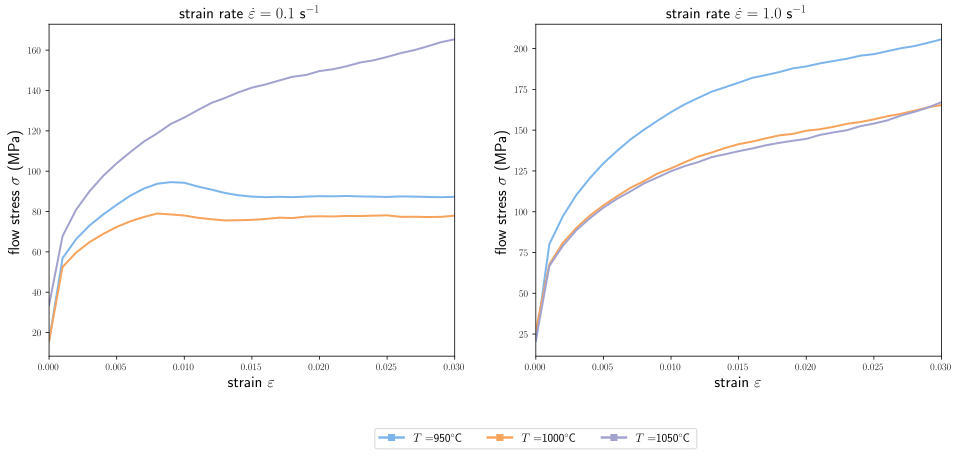

In [5]:
plotDatas(datas, filename='')

<div style="font-size: 28px; font-weight: bold;">ANN Basic Setting</div>

<div style="font-size: 28px; font-weight: bold;">data setting</div>


compute and replace $\dot\varepsilon$ by $\log(\frac{\dot\varepsilon}{\dot\varepsilon_0})$

Compute min and max of ranges

Computes ANNdata

In [ ]:
deps0 = depspArray.min()
print('deps0=',deps0)

# since each noeds in the ANN computation should consider the T depsp strain, so expend the datas to shape of [n,4]
strain_data = np.linspace(0, 0.02 * int(len(datas[0][2])-1), num = len(datas[0][2]))
strain = np.asarray(strain_data)

allData = np.concatenate([
    np.column_stack([
        strain,                              # ε
        np.full(len(strain), d[0]),          # depsp
        np.full(len(strain), d[1]),          # T
        np.asarray(d[2])                     # σ
    ])
    for d in datas
])
print('Format of allData', allData.shape)
# change data 
#change strain_rate
deps0 = depspArray.min()
print('deps0=',deps0)
allData[:,1] = np.log(allData[:,1] / deps0)
# change to ann data
minData = allData.min(axis=0)
maxData = allData.max(axis=0)
rangeData = maxData - minData
annData = (allData - minData) / rangeData

# set input data and output data
annInput = annData[:,0:3]
annOutput = annData[:,3:4]
# quick look of the training data shape
annInput.shape, annOutput.shape



deps0= 0.1
Format of allData (186, 4)
deps0= 0.1


((186, 3), (186, 1))

<div style="font-size: 28px; font-weight: bold;">ANN structure</div>


In [44]:
# basic setting
annTraining = True
models = []
convergences = []

activations = ['sigmoid','tanh', 'relu', 'softplus', 'swish', 'exponential']
shapes = [16, 8]

loss = 'mean_squared_error'
optimizer = 'adam'

# model setting
for activation in activations:
    model = Sequential()
    name = str(3)
    layers = shapes if isinstance(shapes, list) else [shapes]
    for i, n in enumerate(layers):
        if i == 0:
            model.add(Dense(n, input_dim=3, activation=activation, name=f'hl-{i}'))
            name += '-'+str(n)
        else:
            model.add(Dense(n, activation=activation, name=f'hl-{i}'))
    name += '-' + str(n)
    model.add(Dense(1, name = 'output'))
    name += '-' + str(1) + '-' + activation
    model._name = name
    models.append(model)
    model.compile(loss = loss, optimizer = optimizer)   
    convergences.append([name, np.array([])])




make sure all the models have the same initial conditions

In [46]:
model0 = models[0]
for model in models:
    model.set_weights(model0.get_weights())

for model in models:
    model.summary()

Model: "3-16-8-1-sigmoid"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 hl-0 (Dense)                (None, 16)                64        
                                                                 
 hl-1 (Dense)                (None, 8)                 136       
                                                                 
 output (Dense)              (None, 1)                 9         
                                                                 
Total params: 209
Trainable params: 209
Non-trainable params: 0
_________________________________________________________________
Model: "3-16-8-1-tanh"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 hl-0 (Dense)                (None, 16)                64        
                                                                 
 hl-1 (Dense)                

In [47]:
for convergence in convergences:
    print(convergence)

['3-16-8-1-sigmoid', array([], dtype=float64)]
['3-16-8-1-tanh', array([], dtype=float64)]
['3-16-8-1-relu', array([], dtype=float64)]
['3-16-8-1-softplus', array([], dtype=float64)]
['3-16-8-1-swish', array([], dtype=float64)]
['3-16-8-1-exponential', array([], dtype=float64)]


<div style="font-size: 28px; font-weight: bold;">ANN Training</div>


In [ ]:
#basic setting
epochs = 601
maxIterations = 10
savePeriod = 50
annTraining = False

from sklearn.model_selection import train_test_split
x_train, x_valid, y_train, y_valid = train_test_split(annInput, annOutput, test_size = 0.25, shuffle = True)
x_train.shape, x_valid.shape, y_train.shape, y_valid.shape



#train route

if annTraining:
    for model, convergence in zip (models, convergences):
        print("Start to train model :", model.name)
        iteration = 0
        lastMeanLoss = 1
        while(iteration < maxIterations):
            history = model.fit(x_train, y_train, epochs = epochs, use_multiprocessing = True, verbose = 0, shuffle = True, validation_data=(x_valid, y_valid))
            loss = np.array(history.history['loss'])
            meanLoss = loss.mean()
            convergence[1] = np.append(convergence[1], loss)
            iteration += 1
            print('Iteration :', iteration, ': loss =', meanLoss, ': reduction =', lastMeanLoss - meanLoss)
            lastMeanLoss = meanLoss
            if (iteration % savePeriod):
                # Save Tensorflow model
                model.save(DataFile + '/' + model.name + '.h5')
                # Save convergence data
                writeArrayH5(DataFile + '/' + model.name + '-conv.h5', 'data', convergence[1])
        print('End of tranning phase with %g iterations and %g loops' %(iteration, iteration*epochs))
        # Save Tensorflow model
        model.save(DataFile + '/' + model.name + '.h5')
        # Save model manually
        writeAnnH5(DataFile + '/' + model.name + '-ANN.h5')
        # Save convergence data
        writeArrayH5(DataFile + '/' + model.name + '-conv.h5', 'data', convergence[1])
else:
    for model, convergence in zip (models, convergences):
        try:
            # Load Tensorflow model
            model.load_weights(DataFile + '/' + model.name + '.h5')
            # Load convergence data
            convergence[1] = readArrayH5(DataFile + '/' + model.name + '-conv.h5', 'data')
        except:
            continue

((139, 3), (47, 3), (139, 1), (47, 1))